In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import io
import glob
import pandas as pd
import numpy as np
from scipy.spatial import KDTree

def read_well_data(well_file_path):
    """
    Безопасное считывание файла скважин. Удаляет текстовые заголовки, если они есть.
    """
    # Читаем все колонки как текст, чтобы не упасть на заголовках
    df_wells = pd.read_csv(well_file_path, sep=r'\s+', names=['X', 'Y', 'WellName', 'Heff'], dtype=str)
    
    # Принудительно переводим координаты в числа. Заголовки (типа 'X', 'Y') превратятся в NaN
    df_wells['X'] = pd.to_numeric(df_wells['X'], errors='coerce')
    df_wells['Y'] = pd.to_numeric(df_wells['Y'], errors='coerce')
    df_wells['Heff'] = pd.to_numeric(df_wells['Heff'], errors='coerce')
    
    # Удаляем строки, где X или Y не стали числами (т.е. бывшие строки заголовков)
    df_wells = df_wells.dropna(subset=['X', 'Y'])
    
    return df_wells


def read_hr_slice(file_path):
    """
    Безопасное считывание файлов HampsonRussell.
    """
    # Имя колонки по умолчанию (имя файла без расширения)
    val_column_name = os.path.splitext(os.path.basename(file_path))[0]
    
    body_started = False
    data_lines = []
    
    with open(file_path, 'r', encoding='utf-8') as f:
        for line in f:
            if '#{BODY}' in line:
                body_started = True
                continue
                
            if body_started:
                cleaned_line = line.strip()
                if not cleaned_line:
                    continue
                
                # Если строка содержит имя атрибута, пытаемся его вытащить
                if 'Value:' in cleaned_line:
                    parts = cleaned_line.split('Value:')
                    if len(parts) > 1:
                        # Убираем знак '>' в конце названия
                        val_column_name = parts[1].replace('>', '').strip()
                    continue
                
                data_lines.append(cleaned_line)
                    
    data_str = '\n'.join(data_lines)
    
    # Читаем как текст, чтобы Pandas не ругался на строки вида "<X> <Y>"
    df_slice = pd.read_csv(io.StringIO(data_str), sep=r'\s+', names=['X', 'Y', 'Value'], dtype=str)
    
    # Конвертируем в числа. Все не-числа станут NaN
    df_slice['X'] = pd.to_numeric(df_slice['X'], errors='coerce')
    df_slice['Y'] = pd.to_numeric(df_slice['Y'], errors='coerce')
    df_slice['Value'] = pd.to_numeric(df_slice['Value'], errors='coerce')
    
    # Очищаем от строк-заголовков (где X или Y превратились в NaN)
    df_slice = df_slice.dropna(subset=['X', 'Y'])
    
    # Исключаем Null Value (-1.0000e+36)
    df_slice = df_slice[df_slice['Value'] > -1e30] 
    
    return df_slice, val_column_name

def plot_hr_slice_map(file_path, df_wells=None, save_path=None):
    """
    Считывает один файл HampsonRussell и строит по нему карту (Grid Map).
    Если передана таблица df_wells, наносит на карту точки устьев скважин.
    """
    # 1. Читаем данные файла с помощью нашей безопасной функции
    df_slice, col_name = read_hr_slice(file_path)
    
    if df_slice.empty:
        print(f"Нечего визуализировать: файл {file_path} не содержит валидных данных.")
        return

    # 2. Создаем фигуру для рисования
    plt.figure(figsize=(12, 10))
    
    # 3. Строим карту распределения значений
    # tricontourf автоматически строит изолинии и закрашивает интервалы между ними
    # cmap='viridis' или 'jet', 'plasma', 'seismic' — можно выбрать любую палитру
    contour = plt.tricontourf(df_slice['X'], df_slice['Y'], df_slice['Value'], 
                              levels=50, cmap='jet')
    
    # Добавляем цветовую шкалу (легенду) справа
    cbar = plt.colorbar(contour)
    cbar.set_label(f"Значение свойства ({col_name})", fontsize=12, labelpad=10)
    
    # 4. Если переданы данные по скважинам, наносим их устья поверх карты
    if df_wells is not None and not df_wells.empty:
        # Рисуем точки скважин (черные кружки с белой обводкой)
        plt.scatter(df_wells['X'], df_wells['Y'], color='black', edgecolors='white', 
                    s=80, marker='o', zorder=5, label='Скважины')
        
        # Подписываем названия скважин чуть выше их точек
        for idx, row in df_wells.iterrows():
            # Если WellName в индексе, используем idx, если в колонке — row['WellName']
            well_label = idx if 'WellName' not in df_wells.columns else row['WellName']
            plt.text(row['X'], row['Y'] + 15, str(well_label), 
                     fontsize=9, fontweight='bold', color='black',
                     bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1),
                     zorder=6)
        plt.legend(loc='upper right')

    # 5. Оформление осей и заголовков
    plt.title(f"Карта распределения параметра: {col_name}", fontsize=12, fontweight='bold', pad=15)
    plt.xlabel("Координата X (м)", fontsize=10)
    plt.ylabel("Координата Y (м)", fontsize=10)
    
    # Делаем масштаб осей X и Y одинаковым, чтобы карта не искажалась (1 метр по X = 1 метру по Y)
    plt.gca().set_aspect('equal', adjustable='box')
    
    # Включаем сетку
    plt.grid(True, linestyle='--', alpha=0.5)
    
    # Корректируем поля вокруг карты
    plt.tight_layout()
    
    # 6. Сохранение или вывод на экран
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Карта успешно сохранена в файл: {save_path}")
    
    plt.show()




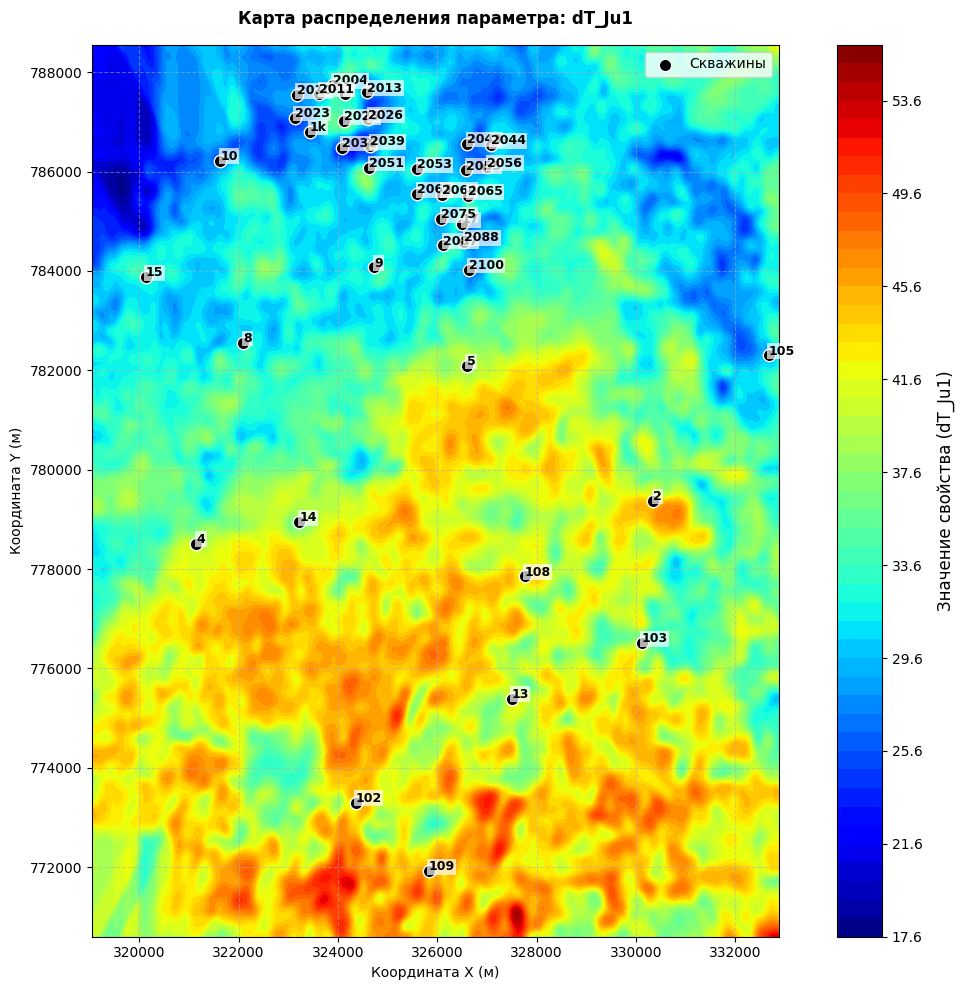

In [20]:
WELLS_FILE = "./DATA_WELLS/Heff_Ju1.txt"
df_wells = read_well_data(WELLS_FILE) 
    
    # Выбираем ОДИН конкретный файл для визуализации из вашей папки
TEST_FILE = './DATA_SLICES/dT_Ju1.txt' 
    
    # Строим карту и сразу наносим на неё скважины
plot_hr_slice_map(file_path=TEST_FILE, df_wells=df_wells)#, #save_path='hr_slice_map.png')